# HDT 6: Boosting e Inferencia Causal

**Ciencia de Datos, Sección A** · Asignada: martes 6 de octubre · **Entrega: martes 13 de octubre, 23:59**

**Nombre:** Milton Orlando Beltrán

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Dos historias, dos datasets:

**Repartos** (partes A y B): una repartidora quiere predecir cuántos `minutos` toma cada entrega, con `distancia` (km) y `paquetes`. Es el mismo tipo de problema que las tiendas de la sesión 18.

**Socios y el curso de finanzas** (parte C): el banco ofrece un curso de finanzas personales y observa que quienes lo tomaron pagan más puntual. ¿El curso causa la puntualidad? El mismo tipo de trampa que la app de la sesión 19.

Las celdas generan los datos completas; no hay nada que llenar aquí.

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(6)
m = 350
distancia = rng.uniform(1, 20, m).round(1)
paquetes = rng.integers(1, 9, m)
minutos = (12 + 2.6 * distancia + 3.5 * paquetes + 0.15 * distancia * paquetes
           + rng.normal(0, 6, m)).round(1)
repartos = pd.DataFrame({"distancia": distancia, "paquetes": paquetes, "minutos": minutos})

R_train, R_test = train_test_split(repartos, test_size=0.3, random_state=1)
Xr, yr = R_train[["distancia", "paquetes"]], R_train["minutos"]
Xr_test, yr_test = R_test[["distancia", "paquetes"]], R_test["minutos"]
print("repartos:", len(R_train), "entrenamiento |", len(R_test), "prueba",
      "| promedio del entrenamiento:", round(yr.mean(), 1), "min")

rng_c = np.random.default_rng(60)
n = 2000
antiguedad = rng_c.integers(0, 20, n)
curso = (rng_c.random(n) < 1 / (1 + np.exp(-(antiguedad - 10) / 3))).astype(int)
puntual = (rng_c.random(n) < 1 / (1 + np.exp(-(-0.3 + (antiguedad - 10) / 4)))).astype(int)
socios = pd.DataFrame({"antiguedad": antiguedad, "curso": curso, "puntual": puntual})
print("socios:", len(socios), "| tomaron el curso:", socios["curso"].mean().round(2),
      "| pagan puntual:", socios["puntual"].mean().round(2))

repartos: 245 entrenamiento | 105 prueba | promedio del entrenamiento: 62.6 min
socios: 2000 | tomaron el curso: 0.48 | pagan puntual: 0.42


## Parte A · Boosting: árboles en fila (0.5 pt)

La sesión 18 con otra flota: cada árbol aprende lo que al anterior le faltó, y se agrega una fracción de su corrección.

### Ejercicio 1 (0.20): el paso 0 y el primer árbol

(a) El paso 0: predecir el promedio del entrenamiento para todos. ¿Cuál es el error absoluto promedio en prueba de ese modelo? (b) Entrenar un `DecisionTreeRegressor(max_depth=2, random_state=0)` sobre **lo que falta** (`yr - promedio`). (c) Armar la tabla de los primeros 3 repartos de prueba: minutos reales, predicción del paso 0, lo que falta, lo que agrega el árbol (la mitad de su corrección: paso 0.5) y la nueva predicción.

In [3]:
from sklearn.tree import DecisionTreeRegressor

promedio = yr.mean()
error_promedio = abs(yr_test - promedio).mean()   # ¿Qué va aquí? error absoluto promedio en prueba usando solo el promedio

arbol1 = DecisionTreeRegressor(max_depth=2, random_state=0).fit(Xr, yr - promedio)  # árbol de profundidad 2 sobre lo que falta

tabla = R_test.head(3).copy()
tabla["pred0"] = round(promedio, 1)
tabla["falta"] = tabla["minutos"] - tabla["pred0"]  # minutos reales menos pred0
tabla["agrega"] = 0.5 * arbol1.predict(tabla[["distancia", "paquetes"]])  # 0.5 * lo que dice el árbol para esos repartos
tabla["nueva"] = tabla["pred0"] + tabla["agrega"]
# imprimir la tabla

print(tabla)
# Verificación (descomentar):
assert round(error_promedio, 1) == 19.7
assert round(tabla["agrega"].iloc[1], 1) == 15.2
assert round(tabla["nueva"].iloc[1], 1) == 77.8

     distancia  paquetes  minutos  pred0  falta     agrega      nueva
192       10.6         4     49.8   62.6  -12.8  -2.574082  60.025918
256       14.8         5     85.3   62.6   22.7  15.245009  77.845009
169       12.8         4     67.1   62.6    4.5   2.553756  65.153756


### Ejercicio 2 (0.15): la fila completa

Completar `boosting_a_mano`: en cada vuelta, entrenar un árbol de profundidad 2 sobre lo que falta, sumar `paso` veces su corrección a las predicciones (de entrenamiento y de prueba) y guardar el error de prueba. Correrla con 8 árboles y paso 0.5.

In [4]:
def boosting_a_mano(X, y, X_nuevo, y_nuevo, n_arboles, paso):
    pred = np.full(len(y), y.mean())
    pred_nuevo = np.full(len(y_nuevo), y.mean())
    errores = []
    for _ in range(n_arboles):
        arbol = DecisionTreeRegressor(max_depth=2, random_state=0).fit(X, y - pred)
        correccion = arbol.predict(X)
        pred += paso * correccion
        correccion_nuevo = arbol.predict(X_nuevo)
        pred_nuevo += paso * correccion_nuevo
        error = np.abs(y_nuevo - pred_nuevo).mean()
        errores.append(error)
    return errores

errores = boosting_a_mano(Xr, yr, Xr_test, yr_test, n_arboles=8, paso=0.5)
# imprimir la lista
print(errores)
# Verificación (descomentar):
assert round(errores[0], 1) == 12.7
assert round(errores[-1], 1) == 5.7

[np.float64(12.733530427317199), np.float64(9.673735437232562), np.float64(7.369366207088389), np.float64(6.6336051766535284), np.float64(6.22290851232483), np.float64(5.981123323902204), np.float64(5.841445884200683), np.float64(5.713425408828422)]


### Ejercicio 3 (0.15): qué tanto corregir en cada paso

Correr `boosting_a_mano` con 8 árboles y pasos 0.1, 0.5 y 1.0. Graficar las tres curvas de error (una línea por paso) y responder en un comentario: ¿cuál termina mejor, y qué le pasa a cada extremo?

paso 0.1 | error final en prueba: 11.20
paso 0.5 | error final en prueba: 5.71
paso 1.0 | error final en prueba: 6.51


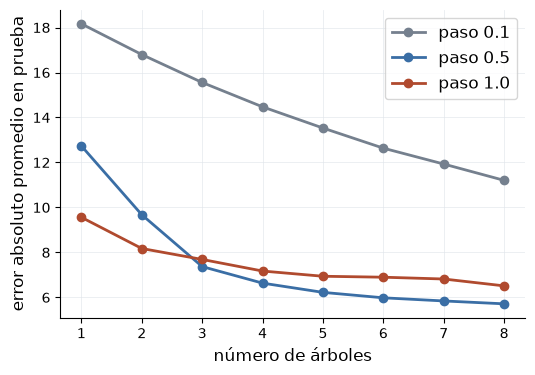

In [5]:
finales = {}
  # ¿Qué va aquí? las tres corridas, la gráfica y finales[paso] = último error
pasos = [0.1, 0.5, 1.0]

fig, ax = plt.subplots(figsize=(6, 4))
for paso, color in zip(pasos, [GRIS, AZUL, ROJO]):
      errores = boosting_a_mano(Xr, yr, Xr_test, yr_test, n_arboles=8, paso=paso)
      ax.plot(range(1, 9), errores, "o-", color=color, lw=2, label=f"paso {paso}")
      finales[paso] = errores[-1]
      print(f"paso {paso} | error final en prueba: {finales[paso]:.2f}")

ax.legend(fontsize=12)
ax.set_xlabel("número de árboles", fontsize=12)
ax.set_ylabel("error absoluto promedio en prueba", fontsize=12)
eje_limpio(ax)

# Respuesta: ...
#termina mejor el paso 0.5 (5.71). El 0.1 avanza muy lento, cada árbol agrega solo el 10% de su corrección y después de 8 árboles sigue en 11.2, le faltan muchos más 
# árboles. El 1.0 arranca más rápido (9.56 con un solo árbol) pero corrige todo de golpe y se pasa; se estanca cerca de 6.5 y termina peor que el 0.5.

# Verificación (descomentar):
assert round(finales[0.1], 1) == 11.2
assert round(finales[0.5], 1) == 5.7
assert round(finales[1.0], 1) == 6.5

## Parte B · ¿Bosque o boosting? (0.3 pt)

### Ejercicio 4 (0.15): los tres sobre la misma prueba

Comparar el error absoluto promedio en prueba de: el promedio a secas, un `RandomForestRegressor` (300 árboles, `random_state=0`) y un `HistGradientBoostingRegressor` (`random_state=0`).

In [6]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

bosque = RandomForestRegressor(n_estimators=300, random_state=0)
bosque.fit(Xr, yr)
pred_bosque = bosque.predict(Xr_test)
error_bosque = np.mean(np.abs(pred_bosque - yr_test))

boosting = HistGradientBoostingRegressor(random_state=0)
boosting.fit(Xr, yr)
pred_boosting = boosting.predict(Xr_test)
error_boosting = np.mean(np.abs(pred_boosting - yr_test))

# imprimir los tres errores (el del promedio ya está en error_promedio)

print(f"Error del promedio: {error_promedio:.1f}")
print(f"Error del bosque: {error_bosque:.1f}")
print(f"Error del boosting: {error_boosting:.1f}")

# Verificación (descomentar):
assert round(error_bosque, 1) == 5.4
assert round(error_boosting, 1) == 5.3

Error del promedio: 19.7
Error del bosque: 5.4
Error del boosting: 5.3


### Ejercicio 5 (0.15): parar a tiempo

Entrenar `HistGradientBoostingRegressor(max_iter=500, early_stopping=True, validation_fraction=0.15, random_state=0)`. ¿En cuántos árboles se detuvo (`n_iter_`) de los 500 permitidos? ¿Su error en prueba empeoró respecto al ejercicio 4?

In [7]:
temprano =  HistGradientBoostingRegressor(max_iter=500, early_stopping=True, validation_fraction=0.15, random_state=0)
temprano.fit(Xr, yr)
arboles_usados = temprano.n_iter_
error_temprano = np.mean(np.abs(temprano.predict(Xr_test) - yr_test))

print(f"Árboles usados: {arboles_usados} de 500")
print(f"Error con freno: {error_temprano:.2f} | sin freno (ej. 4): {error_boosting:.2f}")


# Respuesta: 
# Se detuvo en 46 de los 500 árboles permitidos. El error en prueba empeoró un poco , de 5.29 a 5.65 , porque entrena con el 85% de los datos y usa el otro 15% para decidir cuándo parar.

# Verificación (descomentar):
assert arboles_usados == 46
assert round(error_temprano, 1) == 5.6

Árboles usados: 46 de 500
Error con freno: 5.65 | sin freno (ej. 4): 5.29


## Parte C · Inferencia causal (1.0 pt)

La sesión 19 con el curso de finanzas: predecir no es intervenir, y la diferencia cruda casi nunca es el efecto.

### Ejercicio 6 (0.20): la diferencia cruda

La tasa de pago puntual de quienes tomaron el curso contra quienes no. Calcular ambas (en %) y la diferencia. Es el número que el gerente quiere presentar; guardarlo para compararlo después.

In [8]:
tasas = socios.groupby("curso")["puntual"].mean() * 100
dif_cruda = tasas[1] - tasas[0]

# imprimir las dos tasas y la diferencia
print(f"Tasa con curso: {tasas[1]:.1f}%")
print(f"Tasa sin curso: {tasas[0]:.1f}%")
print(f"Diferencia cruda: {dif_cruda:.1f}%")

# Verificación (descomentar):
assert round(dif_cruda, 1) == 35.4

Tasa con curso: 60.7%
Tasa sin curso: 25.3%
Diferencia cruda: 35.4%


### Ejercicio 7 (0.20): comparar dentro de grupos parecidos

Cortar `antiguedad` en tres niveles con `pd.cut(socios["antiguedad"], [-1, 6, 13, 19], labels=["nuevo", "medio", "veterano"])`. Para cada nivel: la tasa puntual con y sin curso, y su diferencia. Reportar el promedio de las tres diferencias y compararlo con la cruda.

In [9]:
socios["nivel"] = pd.cut(socios["antiguedad"], [-1, 6, 13, 19],
                         labels=["nuevo", "medio", "veterano"])

por_nivel = socios.groupby(["nivel", "curso"])["puntual"].mean() * 100
por_nivel = por_nivel.unstack()
dif_por_nivel = por_nivel[1] - por_nivel[0]
dif_promedio = dif_por_nivel.mean()

# imprimir la tabla y el promedio
por_nivel["diferencia"] = dif_por_nivel
print(por_nivel.round(1))
print(f"Diferencia promedio: {dif_promedio:.1f} puntos | cruda: {dif_cruda:.1f} puntos")
# Verificación (descomentar):
assert round(dif_por_nivel["medio"], 1) == 0.1
assert round(dif_promedio, 1) == 4.4

curso        0     1  diferencia
nivel                           
nuevo     12.2  20.7         8.6
medio     42.5  42.5         0.1
veterano  73.8  78.2         4.4
Diferencia promedio: 4.4 puntos | cruda: 35.4 puntos


### Ejercicio 8 (0.20): la paradoja de Simpson

Un programa de tutorías, dos cursos. Calcular la tasa de aprobados por fila, y luego la tasa total de cada grupo (con y sin tutor) juntando los dos cursos. ¿Qué se invierte? ¿A cuál número hay que creerle y por qué?

In [10]:
tutorias = pd.DataFrame({
    "curso": ["Cálculo", "Cálculo", "Álgebra", "Álgebra"],
    "tutor": ["no", "sí", "no", "sí"],
    "estudiantes": [300, 100, 100, 300],
    "aprobaron": [255, 92, 60, 207],
})

# (a) columna "tasa" por fila, en %
tutorias["tasa"] = (tutorias["aprobaron"] / tutorias["estudiantes"]) * 100
# (b) tabla total por tutor (sumar estudiantes y aprobados) con su tasa
total = tutorias.groupby("tutor")[["estudiantes", "aprobaron"]].sum()
total["tasa"] = (total["aprobaron"] / total["estudiantes"]) * 100

print(tutorias)
print(total)
# Respuesta: 
# Se invierte el total, dentro de cada curso el tutor gana (Cálculo 92% vs 85%, Álgebra 69% vs 60%), pero juntando los cursos "no" saca 78.75% vs 74.75% de "sí".
# Hay que creerle a la comparación por curso, porque el total mezcla la dificultad: 300 de los 400 con tutor están en Álgebra, el curso difícil.

# Verificación (descomentar):
assert tutorias["tasa"].tolist() == [85.0, 92.0, 60.0, 69.0]
assert round(total.loc["sí", "tasa"], 2) == 74.75 and round(total.loc["no", "tasa"], 2) == 78.75

     curso tutor  estudiantes  aprobaron  tasa
0  Cálculo    no          300        255  85.0
1  Cálculo    sí          100         92  92.0
2  Álgebra    no          100         60  60.0
3  Álgebra    sí          300        207  69.0
       estudiantes  aprobaron   tasa
tutor                               
no             400        315  78.75
sí             400        299  74.75


### Ejercicio 9 (0.20): importante para predecir no es causa

Dos logísticas para predecir `puntual`: el modelo A solo con `curso`; el modelo B con `curso` y `antiguedad`. Comparar el coeficiente de `curso` en cada una. ¿Qué le pasa cuando la causa real entra al modelo?

In [11]:
from sklearn.linear_model import LogisticRegression

modelo_a = LogisticRegression().fit(socios[["curso"]], socios["puntual"])
modelo_b = LogisticRegression().fit(socios[["curso", "antiguedad"]], socios["puntual"])

coef_curso_a = modelo_a.coef_[0][0]
coef_curso_b = modelo_b.coef_[0][0]

# imprimir ambos y el coeficiente de antiguedad en B
print(f"Modelo A | curso: {coef_curso_a:.2f}")
print(f"Modelo B | curso: {coef_curso_b:.2f} | antiguedad: {modelo_b.coef_[0][1]:.2f}")

# Respuesta: ...
# Solo con curso, su coeficiente es 1.50 y parece importante, pero  al meter la antigüedad cae a -0.08 (casi cero) y la antigüedad se lleva el peso (0.24 por año).
# El curso predecía porque lo toman más los veteranos, no porque cause la puntualidad.

# Verificación (descomentar):
assert round(coef_curso_a, 2) == 1.5
assert round(coef_curso_b, 2) == -0.08

Modelo A | curso: 1.50
Modelo B | curso: -0.08 | antiguedad: 0.24


### Ejercicio 10 (0.20): el colisionador, con dos monedas

Tirar dos monedas independientes 4,000 veces (`np.random.default_rng(61).integers(0, 2, 4000)` para cada una, en ese orden). (a) Su correlación: debe ser ~0. (b) Filtrar solo las tiradas donde salió al menos una cara y recalcular la correlación entre las que pasaron el filtro. ¿Qué apareció?

In [12]:
rng_m = np.random.default_rng(61)
moneda1 = rng_m.integers(0, 2, 4000)
moneda2 = rng_m.integers(0, 2, 4000)

corr_sin_filtro = np.corrcoef(moneda1, moneda2)[0, 1]
pasan = (moneda1 == 1) | (moneda2 == 1)     # al menos una cara
corr_filtrada = np.corrcoef(moneda1[pasan], moneda2[pasan])[0, 1]

print(f"Correlación sin filtro: {corr_sin_filtro:.2f}")
print(f"Correlación con filtro: {corr_filtrada:.2f}")

# Respuesta: ...
# Sin filtro las monedas no tienen relación (0.02), pero quedándose solo con las tiradas con al menos una cara aparece una correlación de -0.49.
# El filtro quita el caso "dos sellos": si una salió sello, la otra tuvo que salir cara. Filtrar por algo que depende de las dos fabrica una relación que no existe.

# Verificación (descomentar):
assert abs(corr_sin_filtro) < 0.05
assert round(corr_filtrada, 2) == -0.49

Correlación sin filtro: 0.02
Correlación con filtro: -0.49


## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El gerente propone: "los del curso pagan 35 puntos mejor; hagámoslo obligatorio y la puntualidad sube 35 puntos". Con los ejercicios 6, 7 y 9, explicar qué está mal y qué subida es realista esperar.

**(b)** ¿Qué tendría que hacer el banco para medir el efecto REAL del curso? Describir el diseño en 2-3 líneas y explicar por qué resuelve el problema que los datos observados no pueden resolver.

_(Responder editando esta celda)_

**Respuesta (a):** El gerente asume que los 35.4 puntos de diferencia cruda los causa el curso, pero los que lo toman son sobre todo veteranos, y los veteranos ya pagan más puntual. Comparando socios con antigüedad parecida, la diferencia baja a 4.4 puntos, y en el nivel medio es 0.1. En la logística, al meter la antigüedad, el coeficiente del curso cae de 1.50 a -0.08, prácticamente cero. Lo realista es esperar casi nada de subida, a lo mucho unos pocos puntos.

**Respuesta (b):** Hacer un sorteo, tomar un grupo de socios y elegir al azar quién toma el curso y quién no, y después comparar la puntualidad de los dos grupos. El azar reparte la antigüedad, y cualquier otra cosa que no medimos, igual en los dos grupos, así que la única diferencia entre ellos es el curso.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- **Ejercicio 1:** usé AI (Claude) para corregir el ejercicio. Me  faltaba el `random_state=0`. También calculaba `error_promedio` con `yr` (entrenamiento, da 18.0) en vez de `yr_test` (prueba, da 19.7). Entendí que el paso 0 usa el promedio del entrenamiento pero se evalúa en prueba, y que cada árbol del boosting corrige el error que dejó lo anterior, no la respuesta completa.
- **Ejercicio 7:** usé AI (Claude) para resolver un bug. Calculaba la diferencia con `por_nivel.diff(axis=1)`, que devuelve una tabla con las dos columnas: la columna `0` queda toda en `NaN` (no tiene contra qué restarse) y la `1` trae la diferencia. Al sacarle `.mean()` salía una Series con dos valores en vez de un número, y el `print` fallaba con `TypeError: unsupported format string passed to Series.__format__`. Entendí que lo más claro es restar las columnas directamente, `por_nivel[1] - por_nivel[0]` (con curso menos sin curso), que da una diferencia por nivel; su `.mean()` ya es un solo número.
- **Ejercicio 9:** usé AI (Claude) para resolver un bug. Cambié los `print` de los arreglos `coef_` completos por los coeficientes sueltos con su nombre. Entendí que `coef_[0]` es la fila de pesos del modelo y que el orden de los pesos es el mismo de las columnas: en el modelo B, `coef_[0][0]` es `curso` y `coef_[0][1]` es `antiguedad`.
- **Ejercicio 10:** usé AI (Claude) para entender qué estaba haciendo mal. Calculaba `np.corrcoef(pasan, moneda2)`, que mide la relación entre pasar el filtro y la moneda 2 (salía 0.58), cuando lo que se pide es la correlación entre las dos monedas solo en las tiradas que pasaron. Entendí que `pasan` tiene que ser una máscara de `True`/`False` para filtrar las dos monedas con `moneda1[pasan]` y `moneda2[pasan]`, y que el filtro fabrica la relación negativa: al quitar el caso de dos sellos, si una moneda salió sello la otra tuvo que salir cara.